# COMPASS-DOLPHIN results explorer (1-year run)

Quick look at the post-processed `dolphin_points.parquet`.

* Column overview is built from the parquet **metadata only** (no data is read).
* Only `lon`, `lat`, `temporal_coherence` are loaded up front; any other attribute is read **on demand** (single column, cached).
* Time-series (`DYYYYMMDD`) and their `_std` columns, plus the WKB `geometry`, are never loaded.
* Maps are rendered by binning points onto a regular grid (fast for millions of points), statically with matplotlib and interactively with folium on a basemap.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import matplotlib as mpl
import folium

In [2]:
DATA_FILE = Path("/home/lukas/projects/ADUCAT/data/final_outputs/COMPASS-DOLPHIN/dolphin_points.parquet")

pf = pq.ParquetFile(DATA_FILE)
meta = pf.metadata
print(f"File:        {DATA_FILE}  ({DATA_FILE.stat().st_size / 1e9:.2f} GB)")
print(f"Rows:        {meta.num_rows:,}")
print(f"Columns:     {meta.num_columns}")
print(f"Row groups:  {meta.num_row_groups}")

File:        /home/lukas/projects/ADUCAT/data/final_outputs/COMPASS-DOLPHIN/dolphin_points.parquet  (3.06 GB)
Rows:        6,413,762
Columns:     138
Row groups:  30


## 1. Column overview (metadata only)

In [3]:
schema = pf.schema_arrow
TS_RE = re.compile(r"^D\d{8}$")
TS_STD_RE = re.compile(r"^D\d{8}_std$")

ts_cols = [n for n in schema.names if TS_RE.match(n)]
ts_std_cols = [n for n in schema.names if TS_STD_RE.match(n)]
attr_cols = [n for n in schema.names if n not in ts_cols + ts_std_cols + ["geometry"]]

print(f"Attribute columns:      {len(attr_cols)}")
print(f"Time-series columns:    {len(ts_cols)}  ({ts_cols[0][1:]} -> {ts_cols[-1][1:]})" if ts_cols else "Time-series columns: 0")
print(f"Time-series std cols:   {len(ts_std_cols)}")
print(f"Geometry column:        {'geometry' in schema.names}")

Attribute columns:      29
Time-series columns:    54  (20250109 -> 20251229)
Time-series std cols:   54
Geometry column:        True


In [4]:
def column_summary(pf, columns):
    """Aggregate min / max / null count over all row groups from parquet statistics."""
    idx = {pf.schema_arrow.names[i]: i for i in range(len(pf.schema_arrow.names))}
    rows = []
    for name in columns:
        i = idx[name]
        mins, maxs, nulls, has_stats = [], [], 0, True
        for rg in range(pf.metadata.num_row_groups):
            st = pf.metadata.row_group(rg).column(i).statistics
            if st is None:
                has_stats = False
                continue
            nulls += st.null_count or 0
            if st.has_min_max:
                mins.append(st.min)
                maxs.append(st.max)
        rows.append({
            "column": name,
            "dtype": str(pf.schema_arrow.field(name).type),
            "min": min(mins) if mins else None,
            "max": max(maxs) if maxs else None,
            "null_count": nulls if has_stats else None,
            "null_%": round(100 * nulls / pf.metadata.num_rows, 2) if has_stats else None,
        })
    return pd.DataFrame(rows).set_index("column")

summary = column_summary(pf, attr_cols)
with pd.option_context("display.max_rows", 200, "display.float_format", "{:.4g}".format):
    display(summary)

,dtype,min,max,null_count,null_%
column,,,,,
point_id,int64,1.516e+04,7.153e+06,0,0
row,int32,4,2336,0,0
col,int32,51,2993,0,0
lon,double,16.19,16.58,0,0
lat,double,48.12,48.32,0,0
height,float,188.3,609.6,0,0
local_incidence_angle,float,-0.003782,85.71,0,0
los_east,float,-0.5904,-0.561,0,0
los_north,float,-0.108,-0.1059,0,0


`min` / `max` / `null_count` come from the parquet row-group statistics (cheap, no data read).
Float NaNs that were written as values (not nulls) are not counted in `null_count`; the loaded columns below report NaNs explicitly.

## 2. Load base columns (position + coherence)

In [5]:
BASE_COLS = ["lon", "lat", "temporal_coherence"]

base = pf.read(columns=BASE_COLS).to_pandas()
print(f"Loaded {len(base):,} rows, {base.memory_usage(deep=True).sum() / 1e6:.0f} MB")
display(base["temporal_coherence"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]))
print("NaN temporal_coherence:", int(base["temporal_coherence"].isna().sum()))

Loaded 6,413,762 rows, 128 MB


count    6.413503e+06
mean     7.513689e-01
std      2.255380e-01
min      2.269287e-01
5%       3.869629e-01
25%      5.473633e-01
50%      7.827148e-01
75%      9.799805e-01
95%      9.970703e-01
max      1.000000e+00
Name: temporal_coherence, dtype: float64

NaN temporal_coherence: 259


In [6]:
_col_cache = {}

def load_column(name):
    """Read a single attribute column on demand (cached)."""
    if name in base.columns:
        return base[name]
    if name not in attr_cols:
        raise KeyError(f"{name!r} is not a scalar attribute column. Choose from: {attr_cols}")
    if name not in _col_cache:
        _col_cache[name] = pf.read(columns=[name]).column(0).to_pandas()
    return _col_cache[name]

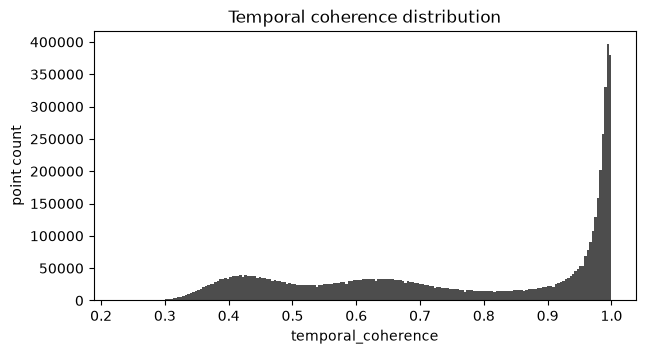

coherence >= 0.3:  6,408,684 points ( 99.9 %)
coherence >= 0.5:  5,101,950 points ( 79.5 %)
coherence >= 0.6:  4,434,466 points ( 69.1 %)
coherence >= 0.7:  3,619,904 points ( 56.4 %)
coherence >= 0.8:  3,140,730 points ( 49.0 %)
coherence >= 0.9:  2,719,053 points ( 42.4 %)


In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(base["temporal_coherence"].dropna(), bins=200, color="0.3")
ax.set_xlabel("temporal_coherence")
ax.set_ylabel("point count")
ax.set_title("Temporal coherence distribution")
plt.show()

for thr in [0.3, 0.5, 0.6, 0.7, 0.8, 0.9]:
    n = int((base["temporal_coherence"] >= thr).sum())
    print(f"coherence >= {thr:.1f}: {n:>10,} points ({100 * n / len(base):5.1f} %)")

## 3. Select attribute and coherence filter

Change the parameters below and re-run the cells that follow.

In [31]:
print("Available attributes:\n", ", ".join(attr_cols))

Available attributes:
 point_id, row, col, lon, lat, height, local_incidence_angle, los_east, los_north, los_up, temporal_coherence, similarity, shp_count, is_ps, amp_dispersion, inversion_residual, conncomp_ok, layover_shadow, velocity_dolphin, mean_velocity, mean_velocity_std, acceleration, acceleration_std, seasonality, seasonality_std, season_peak_doy, season_peak_doy_std, rmse, model_temporal_coherence


In [32]:
COLUMN = "velocity_dolphin"        # any name from attr_cols
MIN_COHERENCE = 0.8             # temporal_coherence threshold (points with NaN coherence are dropped)

PIXEL_SIZE_M = 20               # grid cell size for the map (smaller = more detail, slower)
AGG = "mean"                    # per-cell aggregation: "mean", "median", "min", "max", "count"
CLIM_PERCENTILES = (2, 98)      # colour limits from percentiles of the filtered values
CMAP = "turbo_r"                # matplotlib colormap name; None = automatic (RdBu_r for signed data, viridis otherwise)

In [33]:
values = load_column(COLUMN)
mask = (base["temporal_coherence"] >= MIN_COHERENCE).to_numpy() & values.notna().to_numpy()

df = pd.DataFrame({
    "lon": base["lon"].to_numpy()[mask],
    "lat": base["lat"].to_numpy()[mask],
    COLUMN: values.to_numpy()[mask],
})

print(f"{COLUMN}: {len(df):,} of {len(base):,} points kept "
      f"({100 * len(df) / len(base):.1f} %) at temporal_coherence >= {MIN_COHERENCE}")
display(df[COLUMN].describe(percentiles=[0.02, 0.25, 0.5, 0.75, 0.98]).to_frame().T)

velocity_dolphin: 3,140,730 of 6,413,762 points kept (49.0 %) at temporal_coherence >= 0.8


,count,mean,std,min,2%,25%,50%,75%,98%,max
velocity_dolphin,3140730.0,-1.188881,4.347239,-170.240173,-9.917472,-3.483577,-0.714217,1.508395,4.777706,108.740143


In [34]:
def grid_points(df, column, pixel_size_m=20, agg="mean"):
    """Bin points onto a regular lon/lat grid. Returns (2D array, (west, south, east, north))."""
    lat0 = np.deg2rad(df["lat"].mean())
    dlat = pixel_size_m / 111_320.0
    dlon = pixel_size_m / (111_320.0 * np.cos(lat0))

    west, east = df["lon"].min(), df["lon"].max()
    south, north = df["lat"].min(), df["lat"].max()
    nx = int(np.ceil((east - west) / dlon)) + 1
    ny = int(np.ceil((north - south) / dlat)) + 1

    ix = ((df["lon"].to_numpy() - west) / dlon).astype(np.int64)
    iy = ((north - df["lat"].to_numpy()) / dlat).astype(np.int64)   # row 0 = north
    flat = iy * nx + ix

    if agg == "count":
        cell = np.bincount(flat, minlength=nx * ny).astype(float)
        cell[cell == 0] = np.nan
    elif agg == "mean":
        s = np.bincount(flat, weights=df[column].to_numpy(dtype=float), minlength=nx * ny)
        c = np.bincount(flat, minlength=nx * ny)
        with np.errstate(invalid="ignore", divide="ignore"):
            cell = s / c
    else:
        g = pd.Series(df[column].to_numpy(dtype=float)).groupby(flat).agg(agg)
        cell = np.full(nx * ny, np.nan)
        cell[g.index.to_numpy()] = g.to_numpy()

    extent = (west, north - ny * dlat, west + nx * dlon, north)
    return cell.reshape(ny, nx), extent


def color_settings(data, cmap=None, pct=(2, 98)):
    """Colour limits from percentiles; symmetric around 0 for signed data (e.g. velocities)."""
    lo, hi = np.nanpercentile(data, pct)
    signed = lo < 0 < hi
    if signed:
        m = max(abs(lo), abs(hi))
        lo, hi = -m, m
    if cmap is None:
        cmap = "RdBu_r" if signed else "viridis"
    return cmap, lo, hi


grid, (west, south, east, north) = grid_points(df, COLUMN, PIXEL_SIZE_M, AGG)
cmap, vmin, vmax = color_settings(df[COLUMN] if AGG != "count" else grid, CMAP, CLIM_PERCENTILES)
label = f"{COLUMN} ({AGG})" if AGG != "count" else "point count"
print(f"Grid {grid.shape[1]} x {grid.shape[0]} cells @ {PIXEL_SIZE_M} m, colour range [{vmin:.3g}, {vmax:.3g}]")

Grid 1451 x 1144 cells @ 20 m, colour range [-9.92, 9.92]


### 3a. Static map

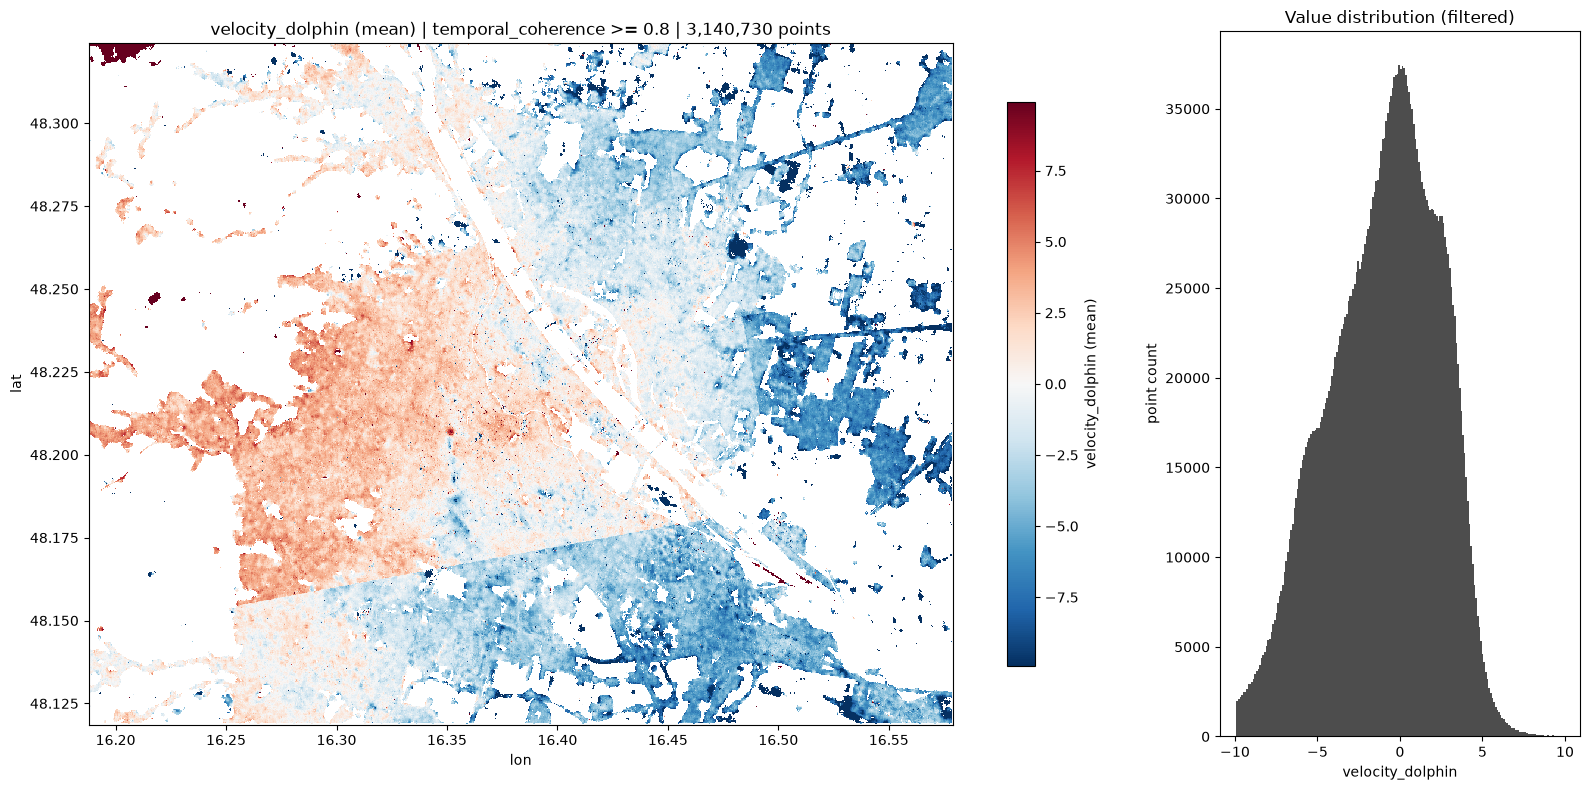

In [35]:
fig, (ax, axh) = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [3, 1]})

aspect = 1 / np.cos(np.deg2rad((north + south) / 2))
im = ax.imshow(grid, extent=(west, east, south, north), cmap=cmap, vmin=vmin, vmax=vmax,
               interpolation="nearest", aspect=aspect)
fig.colorbar(im, ax=ax, label=label, shrink=0.8)
ax.set_xlabel("lon")
ax.set_ylabel("lat")
ax.set_title(f"{label} | temporal_coherence >= {MIN_COHERENCE} | {len(df):,} points")

axh.hist(df[COLUMN], bins=200, range=(vmin, vmax) if AGG != "count" else None, color="0.3")
axh.set_xlabel(COLUMN)
axh.set_ylabel("point count")
axh.set_title("Value distribution (filtered)")
plt.tight_layout()
plt.show()

### 3b. Interactive map (basemap)


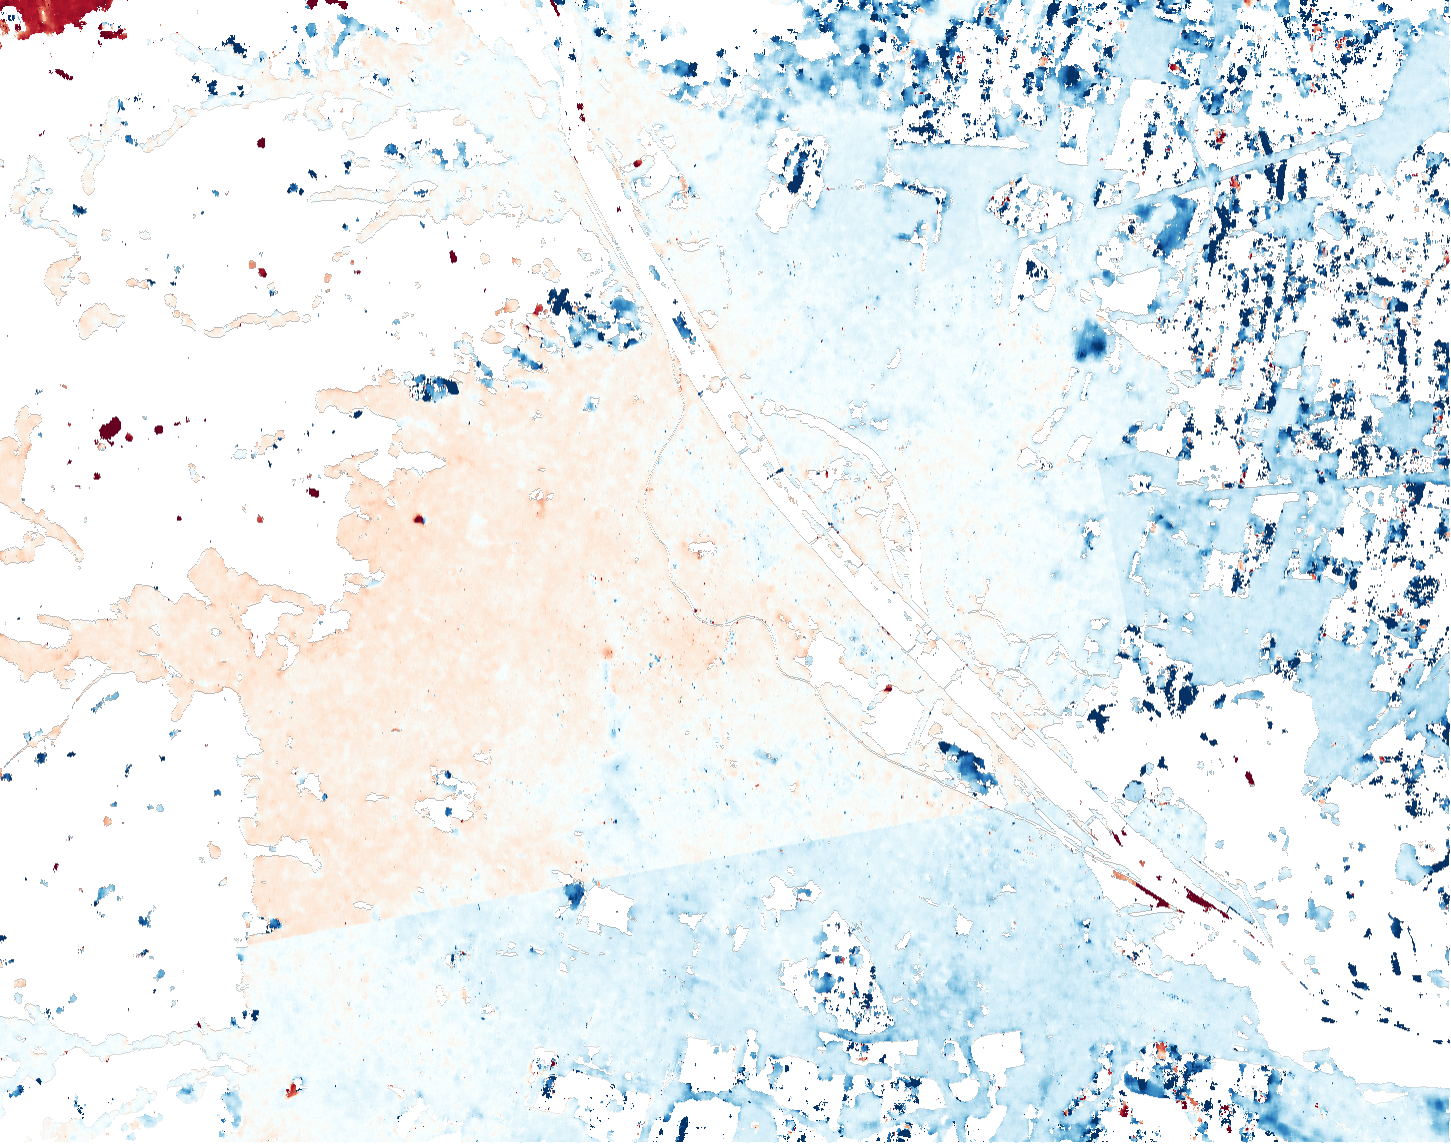

In [19]:
def grid_to_rgba(grid, cmap, vmin, vmax):
    norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
    rgba = mpl.colormaps[cmap](norm(grid))
    rgba[np.isnan(grid), 3] = 0.0     # transparent where no data
    return (rgba * 255).astype(np.uint8)


def colorbar_html(cmap, vmin, vmax, label, n=10):
    stops = ", ".join(mpl.colors.to_hex(mpl.colormaps[cmap](i / (n - 1))) for i in range(n))
    return f"""
    <div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999; background: white;
                padding: 6px 10px; border-radius: 4px; box-shadow: 0 0 4px rgba(0,0,0,.4); font: 12px sans-serif;">
      <div style="margin-bottom: 4px;"><b>{label}</b></div>
      <div style="width: 220px; height: 12px; background: linear-gradient(to right, {stops});"></div>
      <div style="display: flex; justify-content: space-between;"><span>{vmin:.3g}</span><span>{vmax:.3g}</span></div>
    </div>"""


m = folium.Map(location=[(south + north) / 2, (west + east) / 2], zoom_start=13, tiles=None, control_scale=True)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(m)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery", name="Esri Satellite",
).add_to(m)

folium.raster_layers.ImageOverlay(
    image=grid_to_rgba(grid, cmap, vmin, vmax),
    bounds=[[south, west], [north, east]],
    mercator_project=True,
    opacity=0.85,
    name=f"{label} (coh >= {MIN_COHERENCE})",
).add_to(m)

folium.LayerControl().add_to(m)
m.get_root().html.add_child(folium.Element(colorbar_html(cmap, vmin, vmax, label)))
m

## 4. Burst-edge check: S1A vs S1C

Since spring 2025, Sentinel-1A and Sentinel-1C fly the same orbit 6 days apart. The dates are split into:

* **group A**: the 12-day series of the reference date (assumed S1A),
* **group B**: the dates 6 days off that series (assumed S1C).

If an S1A–S1C pair is slightly misaligned in azimuth, TOPS turns this into a phase jump at every burst (and subswath) edge.
Phase unwrapping errors would instead be whole cycles of about 28 mm on single dates.

The check works in two parts:

1. **Offset map.** For every group-B date with group-A dates 6 days before and after:
   `B − (A_before + A_after) / 2`, averaged over the B dates from `OFFSET_START`.
   Real motion over 6 days is negligible, so what is left is the satellite-dependent offset. It should be
   roughly constant within a burst and jump at the edges.
2. **Edge comparison.** For each edge in `EDGES`: median displacement in a strip on each side, the
   difference per date (coloured by group), and the offset profile across the edge.

Check the group assignment against the SAFE file names (`S1A_...` / `S1C_...`); if it differs, set `GROUP_B_DATES` explicitly.

In [ ]:
import warnings
import pyarrow.compute as pc

EDGE_MIN_COHERENCE = 0.8        # temporal_coherence threshold for this check
GROUP_B_DATES = None            # None = 6 days off the reference 12-day series; or a list like ["D20250328", ...]
OFFSET_START = "2025-06-01"     # group-B dates from here on are used for the offset map and the summary
OFFSET_PIXEL_SIZE_M = 50        # grid cell size of the offset map

STRIP_GAP_M = 150               # leave out points closer than this to the edge
STRIP_WIDTH_M = 500             # strip width on each side (beyond the gap)
PROFILE_HALF_WIDTH_M = 1500     # extent of the offset profile across the edge

# Edges as line segments (lon, lat) -> (lon, lat), located from the offset map below.
# "left" of the direction p1 -> p2 is reported as the first side (e.g. north for a west->east line).
EDGES = {
    "E1 slanted, likely burst edge (west)":     [(16.255, 48.156), (16.468, 48.181)],
    "E2a N-S, likely subswath edge (south)":    [(16.486, 48.130), (16.483, 48.176)],
    "E2b N-S, likely subswath edge (north)":    [(16.492, 48.186), (16.492, 48.240)],
    "E3 slanted, likely burst edge (east)":     [(16.492, 48.243), (16.575, 48.253)],
}

In [ ]:
ts_dates = pd.to_datetime([c[1:] for c in ts_cols], format="%Y%m%d")
ts_days = np.asarray((ts_dates - ts_dates[0]).days)

if GROUP_B_DATES is None:
    if np.any(ts_days % 6 != 0):
        print("Warning: some dates are not on the 6-day grid of the reference date:",
              [c for c, d in zip(ts_cols, ts_days) if d % 6])
    is_b = ts_days % 12 == 6
else:
    is_b = np.isin(ts_cols, GROUP_B_DATES)

date_groups = pd.DataFrame({"date": ts_dates, "group": np.where(is_b, "B", "A")}, index=ts_cols)
print(f"Group A (12-day series of the reference date {ts_dates[0]:%Y-%m-%d}): {(~is_b).sum()} dates")
print(f"Group B (6 days off that series):                         {is_b.sum()} dates")
print("B dates:", ", ".join(f"{d:%Y-%m-%d}" for d in ts_dates[is_b]))

# Group-B dates with group-A dates exactly 6 days before and after
day_to_idx = {d: i for i, d in enumerate(ts_days)}
start_day = (pd.Timestamp(OFFSET_START) - ts_dates[0]).days
triplets = []
for i, d in enumerate(ts_days):
    before, after = day_to_idx.get(d - 6), day_to_idx.get(d + 6)
    if is_b[i] and d >= start_day and before is not None and after is not None \
            and not is_b[before] and not is_b[after]:
        triplets.append((i, before, after))
print(f"\nOffset map uses {len(triplets)} B dates from {OFFSET_START}:",
      ", ".join(f"{ts_dates[i]:%m-%d}" for i, _, _ in triplets))

In [ ]:
M_PER_DEG = 111_320.0

def edge_coords(lon, lat, p1, p2):
    # Position of points relative to the segment p1 -> p2 in metres (local flat approximation).
    # Returns (along, dist, length): along = position along the segment, dist > 0 = left of p1 -> p2.
    coslat = np.cos(np.deg2rad((p1[1] + p2[1]) / 2))
    ex, ey = (p2[0] - p1[0]) * M_PER_DEG * coslat, (p2[1] - p1[1]) * M_PER_DEG
    length = np.hypot(ex, ey)
    ux, uy = ex / length, ey / length
    px = (np.asarray(lon) - p1[0]) * M_PER_DEG * coslat
    py = (np.asarray(lat) - p1[1]) * M_PER_DEG
    return px * ux + py * uy, -px * uy + py * ux, length


def side_names(p1, p2):
    # Compass names of the left and right side of the segment p1 -> p2.
    nx = -(p2[1] - p1[1])
    ny = (p2[0] - p1[0]) * np.cos(np.deg2rad(p1[1]))
    left = ("north" if ny > 0 else "south") if abs(ny) >= abs(nx) else ("east" if nx > 0 else "west")
    return left, {"north": "south", "south": "north", "east": "west", "west": "east"}[left]


# One pass over the row groups: offset per point, and the full time series of the strip points.
read_cols = ["lon", "lat", "temporal_coherence", "mean_velocity"] + ts_cols
offset_parts, strip_parts = [], {name: [] for name in EDGES}
b_idx, a1_idx, a2_idx = (np.array(x) for x in zip(*triplets))

for rg in range(pf.metadata.num_row_groups):
    tb = pf.read_row_group(rg, columns=read_cols)
    tb = tb.filter(pc.greater_equal(tb["temporal_coherence"], EDGE_MIN_COHERENCE))
    blk = tb.to_pandas()
    ts = blk[ts_cols].to_numpy(dtype=np.float32)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)          # all-NaN rows
        off = np.nanmean(ts[:, b_idx] - (ts[:, a1_idx] + ts[:, a2_idx]) / 2, axis=1)
    offset_parts.append(pd.DataFrame({"lon": blk["lon"].to_numpy(), "lat": blk["lat"].to_numpy(),
                                      "s1c_offset": off}))
    for name, (p1, p2) in EDGES.items():
        along, dist, length = edge_coords(blk["lon"], blk["lat"], p1, p2)
        in_strip = ((along >= 0) & (along <= length)
                    & (np.abs(dist) > STRIP_GAP_M) & (np.abs(dist) <= STRIP_GAP_M + STRIP_WIDTH_M))
        if in_strip.any():
            part = blk.loc[in_strip, ["mean_velocity"] + ts_cols]
            part.insert(0, "side", np.where(dist[in_strip] > 0, "left", "right"))
            strip_parts[name].append(part)

offsets = pd.concat(offset_parts, ignore_index=True).dropna(subset=["s1c_offset"])
# The absolute level depends on the reference point; only differences between areas matter.
offsets["s1c_offset"] -= offsets["s1c_offset"].median()
strips = {name: pd.concat(parts, ignore_index=True) for name, parts in strip_parts.items() if parts}

print(f"Offset computed for {len(offsets):,} points (temporal_coherence >= {EDGE_MIN_COHERENCE})")
for name, st in strips.items():
    print(f"  {name}: {st['side'].value_counts().to_dict()}")

### 4a. Offset map (group B minus neighbouring group-A dates)

In [ ]:
grid_off, (w, s, e, n) = grid_points(offsets, "s1c_offset", OFFSET_PIXEL_SIZE_M, "median")
_, lo, hi = color_settings(offsets["s1c_offset"], "RdBu_r", (2, 98))

fig, ax = plt.subplots(figsize=(14, 10))
im = ax.imshow(grid_off, extent=(w, e, s, n), cmap="RdBu_r", vmin=lo, vmax=hi, interpolation="nearest",
               aspect=1 / np.cos(np.deg2rad((s + n) / 2)))
for name, (p1, p2) in EDGES.items():
    ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color="k", lw=1.2)
    ax.annotate(name.split()[0], p2, xytext=(4, 4), textcoords="offset points", fontsize=11, weight="bold")
ax.grid(True, lw=0.3, color="0.5")
ax.set_xlabel("lon")
ax.set_ylabel("lat")
ax.set_title(f"S1C offset: B − mean(A ± 6 days), {len(triplets)} B dates from {OFFSET_START}, "
             f"coherence >= {EDGE_MIN_COHERENCE} (median removed)")
fig.colorbar(im, ax=ax, shrink=0.8, label="offset [mm]")
plt.show()

### 4b. Comparison across each edge

In [ ]:
after = np.asarray(ts_dates >= pd.Timestamp(OFFSET_START))
summary_rows = []

for name, st in strips.items():
    p1, p2 = EDGES[name]
    left, right = side_names(p1, p2)
    med = st.groupby("side")[ts_cols].median()
    if not {"left", "right"} <= set(med.index):
        print(f"{name}: points on one side only, skipped")
        continue
    diff = (med.loc["left"] - med.loc["right"]).to_numpy()

    along, dist, length = edge_coords(offsets["lon"], offsets["lat"], p1, p2)
    near = (along >= 0) & (along <= length) & (np.abs(dist) <= PROFILE_HALF_WIDTH_M)
    profile = offsets.loc[near, "s1c_offset"].groupby(np.round(dist[near] / 50) * 50).median()

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw={"width_ratios": [2, 1]})
    ax1.axhline(0, color="0.6", lw=0.8)
    ax1.axvline(pd.Timestamp(OFFSET_START), color="0.6", lw=0.8, ls="--")
    ax1.plot(ts_dates, diff, color="0.75", lw=0.8, zorder=1)
    for group, colour in [("A", "tab:blue"), ("B", "tab:orange")]:
        sel = date_groups["group"].to_numpy() == group
        ax1.scatter(ts_dates[sel], diff[sel], color=colour, s=24, zorder=2,
                    label=f"group {group}" + (" (reference series)" if group == "A" else " (6 days off)"))
    ax1.set_ylabel(f"{left} − {right} [mm]")
    ax1.set_title(f"{name}: median displacement difference across the edge")
    ax1.legend(loc="upper left")

    ax2.axvline(0, color="0.6", lw=0.8)
    for sign in (-1, 1):
        ax2.axvspan(sign * STRIP_GAP_M, sign * (STRIP_GAP_M + STRIP_WIDTH_M), color="0.85", lw=0)
    ax2.plot(profile.index, profile.to_numpy(), "k.-", ms=3, lw=0.8)
    ax2.set_xlabel(f"distance from edge [m]  (+ = {left}, − = {right})")
    ax2.set_ylabel("S1C offset [mm]")
    ax2.set_title("Offset profile across the edge (grey = strips)")
    plt.tight_layout()
    plt.show()

    vel = st.groupby("side")["mean_velocity"].median()
    a_mean, b_mean = diff[after & ~is_b].mean(), diff[after & is_b].mean()
    summary_rows.append({
        "edge": name,
        "sides": f"{left} − {right}",
        "n_points": f"{(st['side'] == 'left').sum():,} / {(st['side'] == 'right').sum():,}",
        "group A diff [mm]": a_mean,
        "group B diff [mm]": b_mean,
        "B − A [mm]": b_mean - a_mean,
        "mean_velocity diff [mm/yr]": vel["left"] - vel["right"],
    })

print(f"Mean differences over dates from {OFFSET_START}:")
display(pd.DataFrame(summary_rows).set_index("edge").round(2))